# Nyung: 한국인만 읽을 수 있는 욕 감지기
**지금까지 한 것: 베이스라인 평가 + 데이터 준비**

| 섹션 | 내용 |
|---|---|
| 0 | 설치, 드라이브, 경로 |
| 1 | 모듈 파일 (`normalize.py`, `eval_baseline.py`) |
| 2 | UnSmile EDA |
| 3 | 베이스라인 평가 (UnSmile valid, 프로브, KOTOX, 속도) |
| 4 | AI Hub 불러오기 → 라벨 변환 → 정제 → 분할 → 베이스라인 평가 |
| 5 | 말장난형 우회 욕 세트 |


## 0. 설정

In [1]:
# 패키지 설치 (코랩 기본 패키지 외에 필요한 것만)
!pip install -q "transformers>=4.38.0" "accelerate>=0.28.0" "scikit-learn>=1.3.0" koreanize-matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 54.5 MB/s eta 0:00:00


In [2]:
# 드라이브 연결 + 공통 import + 경로
from google.colab import drive
drive.mount("/content/drive")

import os, sys, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib                      # 그래프 한글 깨짐 방지
from sklearn.model_selection import train_test_split

sys.path.append("/content")                      # normalize.py, eval_baseline.py 위치
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 100)

# AI Hub 원본 (드라이브, 깃허브에 올리지 않음)
BASE = "/content/drive/MyDrive/Nyung/유해표현 검출 AI모델 학습용 데이터/1.데이터"
# 전처리 결과 저장 위치
OUT = "/content/drive/MyDrive/Nyung/data/processed"
os.makedirs(OUT, exist_ok=True)

Mounted at /content/drive


## 1. 모듈 파일

In [3]:
%%writefile /content/normalize.py
"""
정규화: 비틀어 쓴 표기를 되돌림 (의미 판단은 하지 않음, 의미는 모델 몫)
level: light / strict / strict_hy (strict + 한영 변환)
"""
import re

CHO  = "ㄱㄲㄴㄷㄸㄹㅁㅂㅃㅅㅆㅇㅈㅉㅊㅋㅌㅍㅎ"
JUNG = "ㅏㅐㅑㅒㅓㅔㅕㅖㅗㅘㅙㅚㅛㅜㅝㅞㅟㅠㅡㅢㅣ"
JONG = "ㄱㄲㄳㄴㄵㄶㄷㄹㄺㄻㄼㄽㄾㄿㅀㅁㅂㅄㅅㅆㅇㅈㅊㅋㅌㅍㅎ"
HANGUL = "가-힣ㄱ-ㅣ"

# 보이지 않는 문자 (zero-width space 등)
ZERO_WIDTH = re.compile(r"[​-‏⁠﻿­]")
# light: 한글 사이에 끼운 숫자·기호 제거 (시1발 → 시발), 띄어쓰기는 건드리지 않음
NOISE_LIGHT  = re.compile(rf"(?<=[{HANGUL}])[0-9!@#$%^&*.,~\-_+=|/\\:;'\"`?<>()\[\]{{}}]+(?=[{HANGUL}])")
# strict: 영문 1~2글자 끼우기도 제거 (시a발 → 시발)
NOISE_STRICT = re.compile(rf"(?<=[{HANGUL}])[0-9A-Za-z!@#$%^&*.,~\-_+=|/\\:;'\"`?<>()\[\]{{}}]{{1,2}}(?=[{HANGUL}])")
# 자음 뒤에 모음 ㅣ 대신 쓴 1, l, I, |, ! (ㅅl발 → ㅅㅣ발)
I_LOOKALIKE = re.compile(r"(?<=[ㄱ-ㅎ])[1lI|!](?=[가-힣ㄱ-ㅣ]|$)")

# 한글 자판으로 친 영문 → 한글 자모 (2벌식)
KEY = dict(zip("qwertyuiopasdfghjklzxcvbnm", "ㅂㅈㄷㄱㅅㅛㅕㅑㅐㅔㅁㄴㅇㄹㅎㅗㅓㅏㅣㅋㅌㅊㅍㅠㅜㅡ"))
KEY.update(dict(zip("QWERTOP", "ㅃㅉㄸㄲㅆㅒㅖ")))


def _fullwidth_ascii(s):
    """전각 영숫자·기호만 반각으로 (한글은 그대로, NFKC는 한글 자모를 바꿔서 사용 안 함)"""
    return "".join(chr(ord(c) - 0xFEE0) if 0xFF01 <= ord(c) <= 0xFF5E else c for c in s)


def compose_jamo(s):
    """흩어진 자모를 음절로: ㅅㅣ발 → 시발"""
    out, i = [], 0
    while i < len(s):
        if i + 1 < len(s) and s[i] in CHO and s[i + 1] in JUNG:
            c, v, t = CHO.index(s[i]), JUNG.index(s[i + 1]), 0
            i += 2
            # 다음 글자가 받침 후보이고, 그 뒤가 모음이 아니면 받침으로 붙임
            if i < len(s) and s[i] in JONG and not (i + 1 < len(s) and s[i + 1] in JUNG):
                t = JONG.index(s[i]) + 1
                i += 1
            out.append(chr(0xAC00 + (c * 21 + v) * 28 + t))
        else:
            out.append(s[i]); i += 1
    return "".join(out)


def fix_hanyoung(text):
    """한영 전환 안 하고 친 글자 복원: tlqkf → 시발, qudtls → 병신
    영문 3글자 이상이 '완전한 한글 음절'로만 바뀔 때만 변환 (game, hello 등은 대부분 그대로)"""
    def conv(m):
        out = compose_jamo("".join(KEY.get(c, KEY.get(c.lower(), c)) for c in m.group()))
        return out if re.fullmatch(r"[가-힣]+", out) else m.group()
    return re.sub(r"[A-Za-z]{3,}", conv, text)


def _vowel(ch):
    code = ord(ch) - 0xAC00
    return None if not 0 <= code < 11172 else (code // 28) % 21


def _has_jong(ch):
    code = ord(ch) - 0xAC00
    return 0 <= code < 11172 and code % 28 != 0


def drop_elongation(s):
    """시이이발 → 시발: 받침 없는 음절 뒤에 같은 모음의 'ㅇ+모음'이 붙은 늘여 쓰기 제거"""
    out = []
    for ch in s:
        code = ord(ch) - 0xAC00
        is_o_vowel = 0 <= code < 11172 and code // 588 == CHO.index("ㅇ") and code % 28 == 0
        if out and is_o_vowel and not _has_jong(out[-1]) and _vowel(out[-1]) is not None \
                and _vowel(out[-1]) == _vowel(ch):
            continue
        out.append(ch)
    return "".join(out)


def collapse_repeats(s, keep=2):
    """같은 글자 반복을 keep개로: ㅋㅋㅋㅋ → ㅋㅋ, !!!!! → !!"""
    return re.sub(r"(.)\1{%d,}" % keep, lambda m: m.group(1) * keep, s)


def join_spaced_syllables(s):
    """한 글자씩 띄어 쓴 구간 붙이기: 시 발 놈 아 → 시발놈아
    (알려진 한계: '놈 또', '야 이' 같은 정상 한 글자 단어도 붙음)"""
    return re.sub(rf"(?<![{HANGUL}])([{HANGUL}](?: [{HANGUL}])+)(?![{HANGUL}])",
                  lambda m: m.group(1).replace(" ", ""), s)


def normalize(text, level="strict"):
    strict = level in ("strict", "strict_hy")
    s = ZERO_WIDTH.sub("", str(text))
    s = _fullwidth_ascii(s)
    s = re.sub(r"\s+", " ", s).strip()
    if level == "strict_hy":                 # 한영 변환은 영문 끼우기 제거보다 먼저
        s = fix_hanyoung(s)
    if strict:
        s = I_LOOKALIKE.sub("ㅣ", s)
        s = NOISE_STRICT.sub("", s)
    else:
        s = NOISE_LIGHT.sub("", s)
    s = compose_jamo(s)
    s = collapse_repeats(s, keep=2)
    if strict:
        s = drop_elongation(s)
        s = join_spaced_syllables(s)
    return s

Writing /content/normalize.py


In [4]:
%%writefile /content/eval_baseline.py
"""
베이스라인 평가: UnSmile 모델을 바꾸지 않고 그대로 썼을 때 욕설을 얼마나 잡는지 측정
  evaluate(df, norm, score_type)  text,label DataFrame 평가
  run_kotox() / run_csv(path)     KOTOX, CSV 평가 세트 일괄 평가
  show_errors(df)                 놓친 욕(FN) / 잘못 막은 정상(FP) 예시
  demo([...]) / latency()         문장 바로 넣어 보기 / 속도 측정
"""
import time
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (precision_recall_fscore_support, confusion_matrix,
                             roc_auc_score, average_precision_score)
from normalize import normalize

NAME = "smilegate-ai/kor_unsmile"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MAX_LEN = 64                                   # AI Hub 문장의 94%가 64토큰 이내, 채팅은 더 짧음
SHOW = ["set", "norm", "score", "n", "precision", "recall", "f1", "fpr", "pr_auc"]

tok = AutoTokenizer.from_pretrained(NAME)
model = AutoModelForSequenceClassification.from_pretrained(NAME).to(DEVICE).eval()

# 라벨 위치 (config에 이름이 없으면 README 순서: 8 = 악플/욕설, 9 = clean)
id2label = {int(k): v for k, v in model.config.id2label.items()}
CURSE_IDX = next((i for i, l in id2label.items() if "욕설" in l), 8)
CLEAN_IDX = next((i for i, l in id2label.items() if l.lower() == "clean"), 9)
print(f"id2label: {id2label}\n악플/욕설 = {CURSE_IDX}, clean = {CLEAN_IDX}, device = {DEVICE}")


def _norm(texts, norm):
    """norm: none / light / strict / strict_hy"""
    texts = [str(t) for t in texts]
    return texts if norm == "none" else [normalize(t, level=norm) for t in texts]


@torch.inference_mode()
def predict_probs(texts, bs=64):
    """문장 리스트 → (N, 10) 라벨별 확률 (다중 라벨이라 sigmoid)"""
    out = []
    for i in range(0, len(texts), bs):
        enc = tok(texts[i:i + bs], padding=True, truncation=True,
                  max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            logits = model(**enc).logits
        out.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(out)


def scores_from(probs, score_type="curse"):
    """curse: 악플/욕설 확률만 봄 / any_hate: 1 - clean (어떤 혐오든 걸리면 차단)"""
    return probs[:, CURSE_IDX] if score_type == "curse" else 1 - probs[:, CLEAN_IDX]


def score_texts(texts, norm="none", score_type="curse"):
    return scores_from(predict_probs(_norm(texts, norm)), score_type)


def evaluate(df, norm="none", score_type="curse", threshold=0.5, name=""):
    """df: text, label(0/1) 열"""
    y = df["label"].astype(int).values
    s = score_texts(df["text"], norm, score_type)
    p = (s >= threshold).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(y, p, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    both = len(set(y)) == 2                    # 정답이 한 종류뿐이면 AUC 계산 불가
    return {
        "set": name, "norm": norm, "score": score_type, "n": len(y),
        "precision": round(prec, 4), "recall": round(rec, 4), "f1": round(f1, 4),
        "fpr": round(fp / (fp + tn), 4) if (fp + tn) else None,   # 정상을 욕으로 막은 비율
        "roc_auc": round(roc_auc_score(y, s), 4) if both else None,
        "pr_auc": round(average_precision_score(y, s), 4) if both else None,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    }


def run_eval(df, name, norms=("none", "strict"), score_types=("curse",)):
    """같은 세트를 정규화 방식 × 판정 방식 조합으로 평가해 표로 출력"""
    res = pd.DataFrame([evaluate(df, nm, st, name=name) for nm in norms for st in score_types])
    print(res[SHOW].to_string(index=False))
    return res


KOTOX = "https://huggingface.co/datasets/ssgyejin/KOTOX-classification/resolve/main/data"

def load_kotox(level="total", split="test"):
    return pd.read_csv(f"{KOTOX}/{level}/{split}.csv")


def run_kotox(levels=("easy", "normal", "hard", "total"), norms=("none", "strict"), score_types=("curse",)):
    res = pd.concat([run_eval(load_kotox(lv, "test"), f"KOTOX-{lv}", norms, score_types) for lv in levels])
    return res.reset_index(drop=True)


def run_csv(path, name, norms=("none", "strict"), score_types=("curse",)):
    return run_eval(pd.read_csv(path), name, norms, score_types)


def show_errors(df, norm="strict", score_type="curse", threshold=0.5, n=10):
    """놓친 욕(FN)과 잘못 막은 정상(FP) 예시"""
    inp = _norm(df["text"], norm)
    d = df.assign(normalized=inp, score=scores_from(predict_probs(inp), score_type))
    fn = d[(d.label == 1) & (d.score < threshold)].sort_values("score")
    fp = d[(d.label == 0) & (d.score >= threshold)].sort_values("score", ascending=False)
    print(f"--- 놓친 욕 (FN) {len(fn)}개 중 {min(n, len(fn))}개 ---")
    print(fn[["text", "normalized", "score"]].head(n).to_string(index=False))
    print(f"\n--- 잘못 막은 정상 (FP) {len(fp)}개 중 {min(n, len(fp))}개 ---")
    print(fp[["text", "normalized", "score"]].head(n).to_string(index=False))
    return fn, fp


def demo(texts, norm="strict"):
    """문장 몇 개를 바로 넣어 보기"""
    inp = _norm(texts, norm)
    for t, n_, pr in zip(texts, inp, predict_probs(inp)):
        print(f"{t!r:28} → {n_!r:24} 욕설 {pr[CURSE_IDX]:.2f} | 혐오(1-clean) {1 - pr[CLEAN_IDX]:.2f}")


@torch.inference_mode()
def latency(sample=("야 이 시1발 놈아", "오늘 날씨 좋네", "ㅅㅣ발 진짜"), runs=200, norm="strict"):
    """한 문장 처리 시간 (정규화 + 토큰화 + 모델), ms"""
    for _ in range(10):                        # 예열
        predict_probs(_norm(sample[:1], norm))
    times = []
    for i in range(runs):
        if DEVICE == "cuda": torch.cuda.synchronize()   # GPU 작업이 끝난 시점까지 재기
        t0 = time.perf_counter()
        predict_probs(_norm([sample[i % len(sample)]], norm))
        if DEVICE == "cuda": torch.cuda.synchronize()
        times.append((time.perf_counter() - t0) * 1000)
    gpu = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
    p50, p95, p99 = np.percentile(times, [50, 95, 99])
    print(f"[{gpu}] p50 {p50:.1f}ms | p95 {p95:.1f}ms | p99 {p99:.1f}ms")
    return times

Writing /content/eval_baseline.py


In [5]:
# 모듈 불러오기-eval_baseline을 import하면 UnSmile 모델을 GPU에 올림
from normalize import normalize
from eval_baseline import *

# 정규화 동작 확인
for t, lv in [("tlqkf 진짜", "strict_hy"), ("ㅅl발", "strict"), ("씨이이이발", "strict"),
              ("시 발 놈 아", "strict"), ("수박 씨 발라 먹자", "strict"), ("game 하자", "strict_hy")]:
    print(f"{lv:9} {t!r:14} → {normalize(t, lv)!r}")

config.json:   0%|          | 0.00/1.52k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/370 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/250k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/721k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

id2label: {0: '여성/가족', 1: '남성', 2: '성소수자', 3: '인종/국적', 4: '연령', 5: '지역', 6: '종교', 7: '기타 혐오', 8: '악플/욕설', 9: 'clean'}
악플/욕설 = 8, clean = 9, device = cuda
strict_hy 'tlqkf 진짜'     → '시발 진짜'
strict    'ㅅl발'          → '시발'
strict    '씨이이이발'        → '씨발'
strict    '시 발 놈 아'      → '시발놈아'
strict    '수박 씨 발라 먹자'   → '수박 씨 발라 먹자'
strict_hy 'game 하자'      → 'game 하자'


## 2. UnSmile EDA
베이스 모델이 어떤 데이터로 학습됐는지 먼저 확인합니다.

In [6]:
# UnSmile 원본 데이터
RAW = "https://raw.githubusercontent.com/smilegate-ai/korean_unsmile_dataset/main"
us_train = pd.read_csv(f"{RAW}/unsmile_train_v1.0.tsv", sep="\t")
us_valid = pd.read_csv(f"{RAW}/unsmile_valid_v1.0.tsv", sep="\t")

for d in (us_train, us_valid):                 # 열 이름 공백 정리 ("기타 혐오" → "기타혐오")
    d.columns = [c.replace(" ", "") for c in d.columns]

HATE = ["여성/가족", "남성", "성소수자", "인종/국적", "연령", "지역", "종교", "기타혐오"]
LABELS = HATE + ["악플/욕설", "clean"]

def add_group(d):
    """다중 라벨을 그룹 하나로 요약: 욕설만 / 욕설+혐오 / 혐오만 / clean"""
    curse, hate = d["악플/욕설"] == 1, d[HATE].sum(axis=1) > 0
    d["group"] = np.select([curse & ~hate, curse & hate, ~curse & hate, d["clean"] == 1],
                           ["욕설만", "욕설+혐오", "혐오만", "clean"], default="기타")
    d["n_labels"] = d[LABELS].sum(axis=1)
    return d

us_train, us_valid = add_group(us_train), add_group(us_valid)
print(us_train.shape, us_valid.shape)

(15005, 14) (3737, 14)


In [7]:
# EDA 함수 (AI Hub에도 재사용)
def eda_structure(df, name):
    print(f"===== [{name}] 구조 =====")
    print(f"행 {df.shape[0]:,}개 / 열 {df.shape[1]}개"); print(df.dtypes.to_string())
    display(df.head())

def eda_missing(df, name, text_col="text"):
    print(f"\n===== [{name}] 결측치 =====")
    na = df.isna().sum()
    print(pd.DataFrame({"결측 개수": na, "비율(%)": (na / len(df) * 100).round(2)}).to_string())
    blank = df[text_col].astype(str).str.strip().eq("").sum()
    print(f"빈 문자열 문장: {blank:,}개")

def eda_duplicates(df, name, text_col="text", label_col="label"):
    print(f"\n===== [{name}] 중복 =====")
    conflict = df.groupby(text_col)[label_col].nunique().loc[lambda s: s > 1]
    print(f"완전히 같은 행: {df.duplicated().sum():,}개")
    print(f"문장만 같은 행: {df.duplicated(subset=[text_col]).sum():,}개")
    print(f"같은 문장인데 라벨이 다름: {len(conflict):,}개")

def check_overlap(a, b, name_a, name_b, text_col="text"):
    """train / test 사이 같은 문장 = 데이터 누수"""
    n = len(set(a[text_col]) & set(b[text_col]))
    print(f"[누수 확인] {name_a} ∩ {name_b} 같은 문장: {n:,}개")
    return n

def eda_labels(df, name, label_col="label"):
    """이진 라벨 개수와 비율"""
    vc = df[label_col].value_counts().sort_index()
    print(f"\n===== [{name}] 라벨 분포 =====")
    print(pd.DataFrame({"개수": vc, "비율(%)": (vc / vc.sum() * 100).round(2)}).to_string())
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    vc.plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"][:len(vc)]); ax[0].set_title(f"{name} 라벨 개수")
    for i, v in enumerate(vc): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
    ax[1].pie(vc, labels=vc.index, autopct="%.1f%%", colors=["#4C78A8", "#E45756"][:len(vc)])
    ax[1].set_title(f"{name} 라벨 비율"); plt.tight_layout(); plt.show()

def eda_multilabel(d, name):
    """UnSmile 다중 라벨: 라벨별 개수 / 그룹 비율 / 문장당 라벨 수"""
    counts = d[LABELS].sum().sort_values(ascending=False)
    print(f"\n===== [{name}] 라벨 분포 =====")
    print(pd.DataFrame({"개수": counts, "비율(%)": (counts / len(d) * 100).round(2)}).to_string())
    g = d["group"].value_counts()
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
    counts.plot.bar(ax=ax[0], color="#4C78A8"); ax[0].set_title(f"{name} 라벨별 문장 수")
    ax[1].pie(g, labels=g.index, autopct="%.1f%%"); ax[1].set_title(f"{name} 그룹 비율")
    d["n_labels"].value_counts().sort_index().plot.bar(ax=ax[2], color="#E45756")
    ax[2].set_title(f"{name} 문장당 라벨 개수"); plt.tight_layout(); plt.show()

def eda_length(df, name, text_col="text", label_col="label", tokenizer=None):
    """글자 수 / 토큰 수 분포 (max_len 결정 근거)"""
    d = df.copy()
    d["char_len"] = d[text_col].astype(str).str.len()
    cols = ["char_len"]
    if tokenizer is not None:
        d["tok_len"] = [len(tokenizer.tokenize(t)) for t in d[text_col].astype(str)]
        cols.append("tok_len")
    print(f"\n===== [{name}] 길이 분포 =====")
    for c in cols:
        p = np.percentile(d[c], [50, 90, 95, 99])
        print(f"{c}: 평균 {d[c].mean():.1f} | 중앙 {p[0]:.0f} | 90% {p[1]:.0f} | 95% {p[2]:.0f} | 99% {p[3]:.0f} | 최대 {d[c].max()}")
    fig, axes = plt.subplots(1, len(cols), figsize=(6 * len(cols), 4))
    for ax, c in zip(np.atleast_1d(axes), cols):
        for lab, g in d.groupby(label_col):
            ax.hist(g[c], bins=50, alpha=0.6, label=f"label {lab}")
        ax.axvline(np.percentile(d[c], 95), color="k", ls="--", label="95%")
        ax.set_title(f"{name} {c} 분포"); ax.legend()
    plt.tight_layout(); plt.show()
    return d

In [8]:
# 구조, 결측, 중복, 누수
eda_structure(us_train, "UnSmile train")
eda_missing(us_train, "UnSmile train", text_col="문장")
eda_duplicates(us_train, "UnSmile train", text_col="문장", label_col="group")
check_overlap(us_train, us_valid, "train", "valid", text_col="문장")

===== [UnSmile train] 구조 =====
행 15,005개 / 열 14개
문장          object
여성/가족        int64
남성           int64
성소수자         int64
인종/국적        int64
연령           int64
지역           int64
종교           int64
기타혐오         int64
악플/욕설        int64
clean        int64
개인지칭         int64
group       object
n_labels     int64


,문장,여성/가족,남성,성소수자,인종/국적,연령,지역,종교,기타혐오,악플/욕설,clean,개인지칭,group,n_labels
0,일안하는 시간은 쉬고싶어서 그런게 아닐까,0,0,0,0,0,0,0,0,0,1,0,clean,1
1,아동성범죄와 페도버는 기록바 끊어져 영원히 고통 받는다. 무슬림 50퍼 근친이다. 10 16까지 IQ 떨어지고 출산 위험은 400% 다.,0,0,0,0,0,0,1,0,0,0,0,혐오만,1
2,"루나 솔로앨범 나왔을 때부터 머모 기운 있었음 ㅇㅇ Keep o doin 진짜 띵곡임 꼭 들어보셈""",0,0,0,0,0,0,0,0,0,1,0,clean,1
3,홍팍에도 어버이연합인가 보내요 뭐 이런뎃글 있는데 이거 어버이연합측에 신고하면 그쪽에서 고소 가능하냐?,0,0,0,0,0,0,0,0,0,1,0,clean,1
4,아놔 왜 여기 댓들은 다 여자들이 김치녀라고 먼저 불렸다! 여자들은 더 심하게 그런다! 이렇게 2개로 싸우냐.. 내가 볼 땐 둘다 나쁜 ...,1,0,0,0,0,0,0,0,0,0,0,혐오만,1



===== [UnSmile train] 결측치 =====
          결측 개수  비율(%)
문장            0    0.0
여성/가족         0    0.0
남성            0    0.0
성소수자          0    0.0
인종/국적         0    0.0
연령            0    0.0
지역            0    0.0
종교            0    0.0
기타혐오          0    0.0
악플/욕설         0    0.0
clean         0    0.0
개인지칭          0    0.0
group         0    0.0
n_labels      0    0.0
빈 문자열 문장: 0개

===== [UnSmile train] 중복 =====
완전히 같은 행: 0개
문장만 같은 행: 1개
같은 문장인데 라벨이 다름: 1개
[누수 확인] train ∩ valid 같은 문장: 0개


0


===== [UnSmile train] 라벨 분포 =====
         개수  비율(%)
clean  3739  24.92
악플/욕설  3143  20.95
인종/국적  1728  11.52
여성/가족  1599  10.66
남성     1347   8.98
종교     1181   7.87
성소수자   1141   7.60
지역     1052   7.01
연령      603   4.02
기타혐오    569   3.79


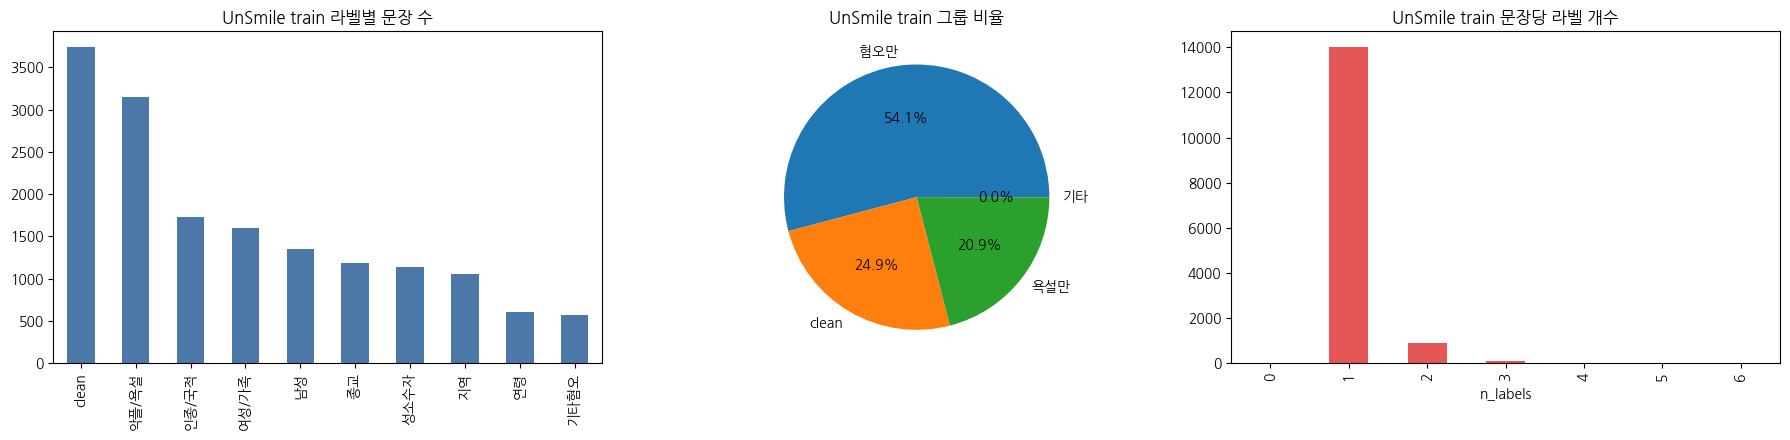


===== [UnSmile valid] 라벨 분포 =====
        개수  비율(%)
clean  935  25.02
악플/욕설  786  21.03
인종/국적  426  11.40
여성/가족  394  10.54
남성     334   8.94
종교     290   7.76
성소수자   280   7.49
지역     260   6.96
연령     146   3.91
기타혐오   134   3.59


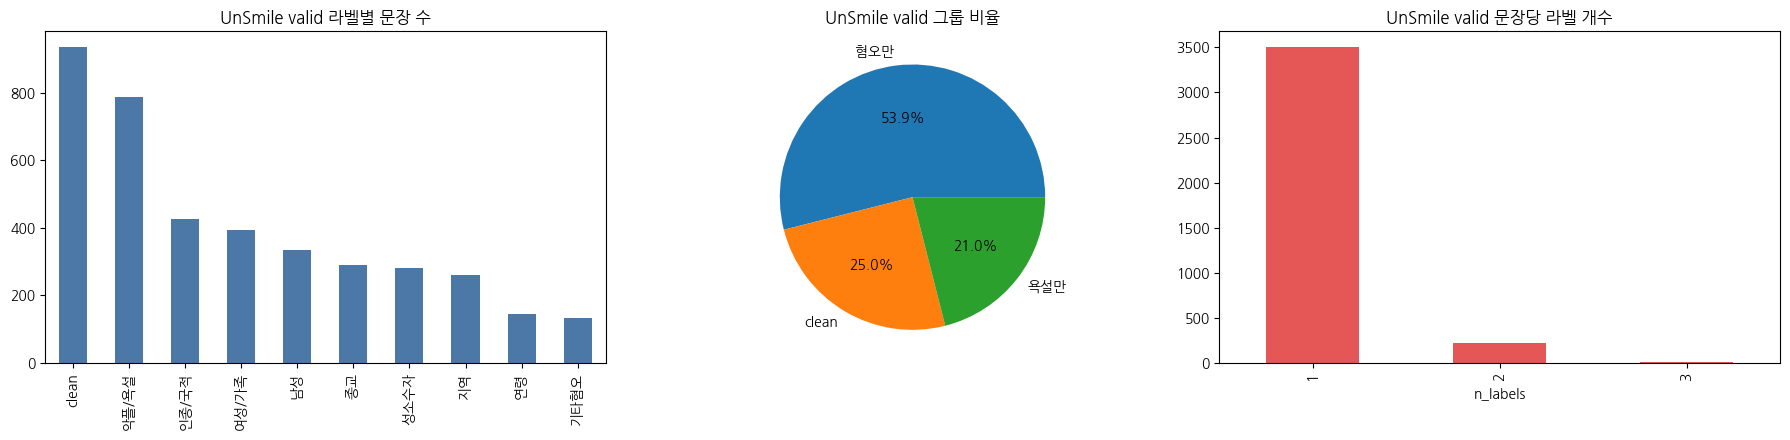

In [9]:
# 라벨 분포 (다중 라벨)
eda_multilabel(us_train, "UnSmile train")
eda_multilabel(us_valid, "UnSmile valid")


===== [UnSmile train] 길이 분포 =====
char_len: 평균 39.8 | 중앙 31 | 90% 82 | 95% 101 | 99% 137 | 최대 155
tok_len: 평균 18.2 | 중앙 14 | 90% 37 | 95% 45 | 99% 61 | 최대 113


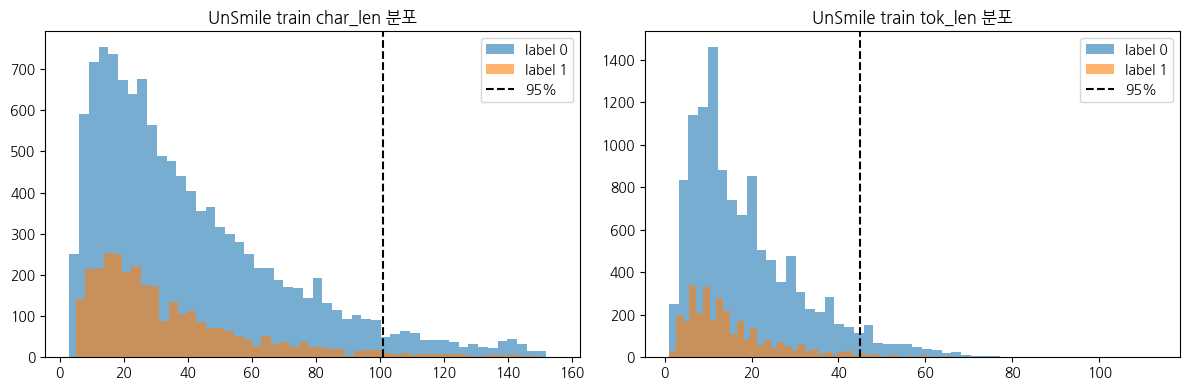

In [10]:
# 길이 분포 (욕설 여부로 나눠서)
us_train["is_curse"] = us_train["악플/욕설"]
_ = eda_length(us_train, "UnSmile train", text_col="문장", label_col="is_curse", tokenizer=tok)

## 3. 베이스라인 평가 (E1)
UnSmile을 **그대로** 썼을 때의 점수임. 학습 후(E2, E3)에 같은 세트로 다시 재서 비교할 것임.

In [11]:
# UnSmile valid: 정규화 방식별 비교 (정답 = 악플/욕설)
valid_eval = us_valid.rename(columns={"문장": "text"}).assign(label=us_valid["악플/욕설"])
res_unsmile = run_eval(valid_eval, "UnSmile valid", norms=("none", "light", "strict", "strict_hy"))

          set      norm score    n  precision  recall     f1    fpr  pr_auc
UnSmile valid      none curse 3737     0.7602  0.5929 0.6662 0.0498  0.7444
UnSmile valid     light curse 3737     0.7728  0.5929 0.6710 0.0464  0.7507
UnSmile valid    strict curse 3737     0.7681  0.5941 0.6700 0.0478  0.7511
UnSmile valid strict_hy curse 3737     0.7685  0.5954 0.6710 0.0478  0.7513


In [12]:
# 문장 바로 넣어 보기: 우회 욕 / 정상 / 오탐 함정
demo(["시1발 진짜", "ㅅㅣ발 놈아", "씨이이발", "시 발 놈 아", "tlqkf",
      "오늘 날씨 좋네", "시발점부터 보자", "수박 씨 발라 먹자"], norm="strict_hy")

'시1발 진짜'                     → '시발 진짜'                  욕설 0.91 | 혐오(1-clean) 0.95
'ㅅㅣ발 놈아'                     → '시발 놈아'                  욕설 0.91 | 혐오(1-clean) 0.94
'씨이이발'                       → '씨발'                     욕설 0.92 | 혐오(1-clean) 0.95
'시 발 놈 아'                    → '시발놈아'                   욕설 0.92 | 혐오(1-clean) 0.95
'tlqkf'                      → '시발'                     욕설 0.90 | 혐오(1-clean) 0.94
'오늘 날씨 좋네'                   → '오늘 날씨 좋네'               욕설 0.06 | 혐오(1-clean) 0.08
'시발점부터 보자'                   → '시발점부터 보자'               욕설 0.90 | 혐오(1-clean) 0.95
'수박 씨 발라 먹자'                 → '수박 씨 발라 먹자'             욕설 0.53 | 혐오(1-clean) 0.75


In [13]:
# 프로브: 유형별로 직접 만든 확인용 문장 (강조 비속어는 욕이 아니라고 판단해 제외)
probe = pd.DataFrame([
    # A. 정규화로 풀리는 우회 (욕)
    ("시1발 진짜", 1, "A_정규화"), ("ㅅㅣ발 놈아", 1, "A_정규화"), ("시 발 놈 아", 1, "A_정규화"),
    ("병1신같네", 1, "A_정규화"), ("씨이이발", 1, "A_정규화"),
    # B. 초성만 (욕)
    ("ㅅㅂ 짜증나", 1, "B_초성"), ("ㅆㅂ 뭐하냐", 1, "B_초성"), ("ㅂㅅ아", 1, "B_초성"),
    ("ㅁㅊㄴ", 1, "B_초성"), ("ㅈㄴ 못하네", 1, "B_초성"),
    # C. 된소리·모음 비틀기 (욕)
    ("씨빨 진짜", 1, "C_비틀기"), ("쉬바 뭐냐", 1, "C_비틀기"), ("시바 꺼져", 1, "C_비틀기"),
    ("십알놈", 1, "C_비틀기"), ("븅신아", 1, "C_비틀기"), ("빙신같은게", 1, "C_비틀기"),
    ("미틴놈", 1, "C_비틀기"), ("닭쳐라", 1, "C_비틀기"), ("개새기", 1, "C_비틀기"), ("개쉐이", 1, "C_비틀기"),
    # D. 한영 변환 (욕)
    ("tlqkf", 1, "D_한영"), ("qudtls", 1, "D_한영"), ("c8 진짜", 1, "D_한영"), ("sibal", 1, "D_한영"),
    # E. 단어 바꿔치기·은어 (욕)
    ("느금마", 1, "E_은어"), ("니애미", 1, "E_은어"), ("몽뭉이 같은 놈", 1, "E_은어"), ("엠창", 1, "E_은어"),
    # F. 욕 없는 모욕
    ("머리는 장식이냐", 1, "F_모욕"), ("너 같은 건 왜 사냐", 1, "F_모욕"), ("부모님이 불쌍하다", 1, "F_모욕"),
    # G. 오탐 함정 (정상)
    ("시발점부터 보자", 0, "G_함정"), ("다음 역이 시발역이야", 0, "G_함정"), ("수박 씨 발라 먹자", 0, "G_함정"),
    ("내 십팔번은 이 노래", 0, "G_함정"), ("병신년은 2016년이다", 0, "G_함정"), ("새끼 고양이 귀여워", 0, "G_함정"),
    ("다음 주 개강이야", 0, "G_함정"), ("18세 이상 관람가", 0, "G_함정"), ("채팅에서 욕하지 마세요", 0, "G_함정"),
    ("닥쳐올 미래가 걱정이다", 0, "G_함정"), ("ㅎㅏㅇ상 고마워", 0, "G_함정"), ("우리 집 개 산책 시켜야 해", 0, "G_함정"),
], columns=["text", "label", "type"])

In [14]:
# 프로브 평가: 유형별 정답률 (정규화 방식별)
NORMS = ("none", "strict", "strict_hy")
for nm in NORMS:
    s = score_texts(probe["text"], nm, "curse")
    probe[f"score_{nm}"] = s.round(2)
    probe[f"ok_{nm}"] = (s >= 0.5).astype(int) == probe["label"]

print(probe.groupby("type")[[f"ok_{nm}" for nm in NORMS]].mean().round(2))

# 틀린 문장만 (가장 강한 정규화 기준)
display(probe.loc[~probe["ok_strict_hy"], ["type", "text", "label"] + [f"score_{nm}" for nm in NORMS]])

       ok_none  ok_strict  ok_strict_hy
type                                   
A_정규화     1.00       1.00          1.00
B_초성      1.00       1.00          1.00
C_비틀기     0.90       0.90          0.90
D_한영      0.50       0.50          1.00
E_은어      0.50       0.50          0.50
F_모욕      0.67       0.67          0.67
G_함정      0.75       0.75          0.75


,type,text,label,score_none,score_strict,score_strict_hy
17,C_비틀기,닭쳐라,1,0.37,0.37,0.37
24,E_은어,느금마,1,0.11,0.11,0.11
25,E_은어,니애미,1,0.28,0.28,0.28
30,F_모욕,부모님이 불쌍하다,1,0.14,0.14,0.14
31,G_함정,시발점부터 보자,0,0.90,0.90,0.90
33,G_함정,수박 씨 발라 먹자,0,0.53,0.53,0.53
35,G_함정,병신년은 2016년이다,0,0.75,0.75,0.75


In [15]:
# KOTOX test (난이도별, 비틀어 쓴 욕 평가)
res_kotox = run_kotox(norms=NORMS)

       set      norm score   n  precision  recall     f1    fpr  pr_auc
KOTOX-easy      none curse 460     0.8151  0.4217 0.5559 0.0957  0.7615
KOTOX-easy    strict curse 460     0.8304  0.4043 0.5439 0.0826  0.7687
KOTOX-easy strict_hy curse 460     0.8304  0.4043 0.5439 0.0826  0.7683
         set      norm score   n  precision  recall     f1   fpr  pr_auc
KOTOX-normal      none curse 460     0.7869  0.4174 0.5455 0.113  0.7378
KOTOX-normal    strict curse 460     0.7797  0.4000 0.5287 0.113  0.7319
KOTOX-normal strict_hy curse 460     0.7797  0.4000 0.5287 0.113  0.7321
       set      norm score   n  precision  recall     f1    fpr  pr_auc
KOTOX-hard      none curse 460     0.7083  0.3696 0.4857 0.1522  0.6605
KOTOX-hard    strict curse 460     0.6972  0.3304 0.4484 0.1435  0.6527
KOTOX-hard strict_hy curse 460     0.6972  0.3304 0.4484 0.1435  0.6538
        set      norm score    n  precision  recall     f1    fpr  pr_auc
KOTOX-total      none curse 1380     0.7701  0.4029 0.5290

In [16]:
# 속도: 한 문장 처리 시간 (정규화 + 모델)
_ = latency(norm="strict_hy")

[Tesla T4] p50 12.2ms | p95 12.9ms | p99 14.8ms


## 4. AI Hub 유해표현 데이터
- stage1: 유해 여부 (content, label)
- stage2: 유형 11개 + 정상 (값 0~3 = 강도)

**라벨 방침:** 욕설·모욕 > 0 → 1 / 정상만 → 0 / 다른 혐오만 → 따로 보관 (학습에 0으로 넣을지는 학습 단계에서 결정)

In [17]:
# 불러오기
s1 = pd.read_csv(f"{BASE}/1. 유해표현 검출/stage1_data.csv")
s2 = pd.read_csv(f"{BASE}/2. 유해 카테고리 분류/stage2_data.csv")
print("stage1", s1.shape, "| stage2", s2.shape)
display(s1.head(3)); display(s2.head(3))

stage1 (200000, 2) | stage2 (200000, 13)


,content,label
0,"""예수쟁이들은 모하냐?저 주둥이를 안 틀어막고?같은 것들이냐?""",1
1,저 #@이름# 때문에 이''꼴'''났디 빨리 ''처'''내려와라 ''신물'''난다,1
2,''쪽팔려'''서 외국에서 얼굴을 못들겠다. ''Fuxx''' MBC너넨 영원히 ''거른'''다.,1


,문장,모욕,욕설,외설,폭력위협/범죄조장,성혐오,연령,인종/지역,장애,종교,정치성향,직업,정상
0,독점은 당연히 막아야지. 이건 사장경제는 경쟁으로 가야 정상순환되는데 독점이 되면 기업이 공산국가처럼 독재하는건데,0,0,0,0,0,0,0,0,0,1,0,0
1,눈 작다고 한 마디 한 걸로 퇴출시키는 그리스가 훨씬 선진국이네 ㅋㅋㅋ MBC는 사과문 ''끄적'''이고 ''버로우 타'''고 있는데,2,0,0,0,0,0,0,0,0,0,0,0
2,''도쿄만 똥물'''도 문제지만 해안에 모래는 후쿠시마 흙으로 채웠는데 이선수들 피폭이 걱정된다,2,0,0,0,0,0,2,0,0,0,0,0


In [18]:
# 분포와 문제 확인
CATS = list(s2.columns[1:])                     # 문장 다음 열부터 유형
for c in CATS:
    print(f"{c:12}", s2[c].value_counts().sort_index().to_dict())

print("\nstage1 라벨:", s1.label.value_counts().to_dict())
print("두 파일 겹치는 문장:", len(set(s1.content) & set(s2["문장"])), "→ stage2만 사용")
print("'' 유해 구간 표시 비율  s1:", s1.content.str.contains("''").mean().round(3),
      "| s2:", s2["문장"].str.contains("''").mean().round(3))
print("#@ 비식별 태그 비율 s1:", s1.content.str.contains("#@").mean().round(3))

모욕           {0: 154231, 2: 43387, 3: 2382}
욕설           {0: 169672, 1: 18073, 2: 10007, 3: 2248}
외설           {0: 197602, 1: 1333, 2: 872, 3: 193}
폭력위협/범죄조장    {0: 193441, 1: 2715, 2: 2983, 3: 861}
성혐오          {0: 195354, 1: 2429, 2: 1845, 3: 372}
연령           {0: 197865, 1: 1175, 2: 844, 3: 116}
인종/지역        {0: 181629, 1: 10155, 2: 6997, 3: 1219}
장애           {0: 198208, 1: 1606, 2: 158, 3: 28}
종교           {0: 198823, 1: 629, 2: 431, 3: 117}
정치성향         {0: 164515, 1: 16330, 2: 16299, 3: 2856}
직업           {0: 191985, 1: 4058, 2: 3566, 3: 391}
정상           {0: 100000, 1: 100000}

stage1 라벨: {1: 100000, 0: 100000}
두 파일 겹치는 문장: 170091 → stage2만 사용
'' 유해 구간 표시 비율  s1: 0.301 | s2: 0.43
#@ 비식별 태그 비율 s1: 0.108


In [19]:
# 라벨 변환
OTHER = [c for c in CATS if c not in ("모욕", "욕설", "정상")]   # 욕설·모욕 외 혐오 유형

def clean(t):
    t = re.sub(r"'{2,}", "", str(t))            # 유해 구간 표시 '' ''' 제거 (지름길 학습 방지)
    t = re.sub(r"#@[^#]*#", "OO", t)            # #@이름# 같은 비식별 태그 → OO
    t = t.replace("\\", "").strip('"')
    return re.sub(r"\s+", " ", t).strip()

ah = s2.rename(columns={"문장": "raw"})
pos   = (ah["모욕"] > 0) | (ah["욕설"] > 0)                          # 욕설·모욕 → 1
neg   = (ah["정상"] == 1) & (ah[OTHER].sum(axis=1) == 0) & ~pos     # 정상만 → 0
other = ~pos & (ah["정상"] == 0)                                     # 다른 혐오만
ah["label"] = np.select([pos, neg], [1, 0], default=-1)              # -1 = 학습 라벨에서 제외
print("변환:", ah["label"].value_counts().to_dict(), "| 다른 혐오만:", other.sum())

# 유해 구간 표시가 욕 쪽에만 몰려 있는지 (몰려 있으면 지우는 게 맞다는 근거)
print("'' 표시 비율 (라벨별):", ah.groupby("label")["raw"].apply(lambda s: s.str.contains("''").mean().round(3)).to_dict())
print("\n욕설 강도 1 샘플:"); print(ah.loc[ah["욕설"] == 1, "raw"].sample(8, random_state=0).to_string())

변환: {0: 100000, 1: 60870, -1: 39130} | 다른 혐오만: 39130
'' 표시 비율 (라벨별): {-1: 0.714, 0: 0.0, 1: 0.953}

욕설 강도 1 샘플:
60956                     요노마도 대통령 까부쳐서 ''국짐당'''한테 잘보여서 담에도 부시장 해''쳐''' 묵을라꼬 ''지랄터네'''\n
11567                                                         대한민국 청와대는 뻥이나 ''쳐'''대고 ?\n
15141                                  한겨레 답다정치꾼들 털어서 먼지 안날''놈'''있으면 말해봐라다 ''도적'''''놈'''
17920                                           이''놈''' 뒤에 #@이름#가 있었네 #@이름#부터 잡아넣고 조사해라ㆍ
25699          ''뻔뻔'''함 ''무능''' ''무식''' ''지랄''' ....''좌파'''들은 부끄러운 줄 모르고 오히려 물려고 하는게 문제다
66015    인간도 아녀 민주노총 이나라 떠나라 양심도 없는 ''놈'''들 니들대문에 확산됐지. 온국민만 또 힘들어지고 중소 상인들이 힘들어지는데 니...
32647    역시  ''빨..걍이'''들은  세월호 가짜선동으로  청와대 붛법점거하더디  4년만에 나라 ''말아먹'''고... 하는짓이 고작  저런거...
95754    \n#@이름#은 이중대 같은 ''놈'''임. #@이름#등 대선 주자는 온갖 비방과 억지로 지지율 떨어 트리고 이 엄청난 #@이름# 캠프 ...


정제 후: 160855 {0: 99999, 1: 60856} | 다른 혐오: 39108

===== [AI Hub 정제 후] 라벨 분포 =====
          개수  비율(%)
label              
0      99999  62.17
1      60856  37.83


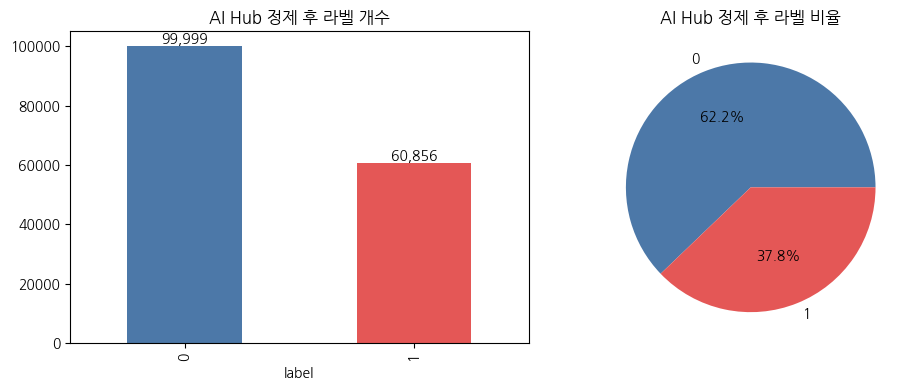

In [20]:
# 정제: 표시·태그 제거 → 짧은 문장 제거 → 라벨 충돌 제거 → 중복 제거 → 평가 세트와 겹치는 문장 제거
def tidy(d):
    d = d.assign(text=d["raw"].map(clean))
    d = d[d["text"].str.len() >= 2]
    conflict = d.groupby("text")["label"].nunique().loc[lambda s: s > 1].index
    return d[~d["text"].isin(conflict)].drop_duplicates("text")[["text", "label"]]

# 평가에 쓰는 문장 (학습에 들어가면 점수가 부풀려짐)
EVAL_TEXTS = set(valid_eval["text"]) | set(load_kotox("total", "test")["text"]) | set(probe["text"])

df  = tidy(ah[ah["label"] >= 0])
oth = tidy(ah[other].assign(label=0))
df  = df[~df["text"].isin(EVAL_TEXTS)]
oth = oth[~oth["text"].isin(EVAL_TEXTS | set(df["text"]))]
print("정제 후:", len(df), df["label"].value_counts().to_dict(), "| 다른 혐오:", len(oth))
eda_labels(df, "AI Hub 정제 후")

In [21]:
# 토큰 길이: MAX_LEN 64로 충분한지 (5,000개 샘플)
tl = df["text"].sample(5000, random_state=0).map(lambda t: len(tok(t)["input_ids"]))
print(tl.describe(percentiles=[.5, .9, .95, .99]).round(1).to_dict())
print("64 초과 비율:", (tl > 64).mean().round(3))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (366 > 300). Running this sequence through the model will result in indexing errors


{'count': 5000.0, 'mean': 29.7, 'std': 22.3, 'min': 5.0, '50%': 23.0, '90%': 54.0, '95%': 70.0, '99%': 121.0, 'max': 366.0}
64 초과 비율: 0.062


In [22]:
# 분할 8:1:1 (중복을 먼저 지웠으므로 같은 문장이 train과 test에 함께 들어가지 않음) → 드라이브 저장
def split_save(d, prefix, stratify=True):
    st = d["label"] if stratify else None
    tr, tmp = train_test_split(d, test_size=0.2, stratify=st, random_state=42)
    va, te = train_test_split(tmp, test_size=0.5, stratify=tmp["label"] if stratify else None, random_state=42)
    for name, part in [("train", tr), ("valid", va), ("test", te)]:
        part.to_csv(f"{OUT}/{prefix}_{name}.csv", index=False)
    print(f"{prefix}: train {len(tr)} / valid {len(va)} / test {len(te)} | 1 비율 {tr['label'].mean():.3f}")
    return tr, va, te

tr, va, te = split_save(df, "aihub")                          # 욕설·모욕 vs 정상
o_tr, o_va, o_te = split_save(oth, "aihub_other", stratify=False)   # 다른 혐오 (전부 0)

aihub: train 128684 / valid 16085 / test 16086 | 1 비율 0.378
aihub_other: train 31286 / valid 3911 / test 3911 | 1 비율 0.000


In [23]:
# 베이스라인을 AI Hub test에서 측정
res_aihub = run_eval(te, "AIHub-test", norms=("none", "strict"), score_types=("curse", "any_hate"))

# 다른 혐오 (전부 정답 0): FPR만 의미 있음. 높을수록 욕 아닌 문장을 많이 막는다는 뜻
res_other = run_eval(o_te, "AIHub-다른혐오", norms=("none",), score_types=("curse", "any_hate"))

       set   norm    score     n  precision  recall     f1    fpr  pr_auc
AIHub-test   none    curse 16086     0.9396  0.5161 0.6662 0.0202  0.8365
AIHub-test   none any_hate 16086     0.9168  0.9520 0.9341 0.0526  0.9807
AIHub-test strict    curse 16086     0.9412  0.5100 0.6616 0.0194  0.8352
AIHub-test strict any_hate 16086     0.9189  0.9481 0.9333 0.0509  0.9807
       set norm    score    n  precision  recall  f1    fpr pr_auc
AIHub-다른혐오 none    curse 3911        0.0     0.0 0.0 0.3731   None
AIHub-다른혐오 none any_hate 3911        0.0     0.0 0.0 0.8507   None


## 5. 말장난형 우회 욕
수박씨 발라먹을 놈, 조카 18색 크레파스 같은 표현. 정규화로는 풀 수 없고(띄어쓰기를 지우면 정상 문장도 걸림), 학습으로 문맥을 가르쳐야 함.

In [24]:
# 기존 데이터에 말장난 표현이 얼마나 있는지 (AI Hub + KOTOX)
PUN_WORDS = ["수박씨", "조카크레파스", "조까", "십장생", "시베리아", "신발끈", "개나리", "18색", "씨발라"]

kotox = pd.concat([load_kotox("total", sp) for sp in ("train", "valid", "test")])
ah_flat = df["text"].str.replace(" ", "")
kx_norm = kotox["text"].astype(str).map(lambda t: normalize(t, "strict_hy").replace(" ", ""))

rows = []
for w in PUN_WORDS:
    a, k = df[ah_flat.str.contains(w)], kotox[kx_norm.str.contains(w)]
    rows.append({"표현": w, "AI Hub": len(a), "AI Hub 욕 비율": round(a.label.mean(), 2) if len(a) else None,
                 "KOTOX": len(k)})
display(pd.DataFrame(rows))

,표현,AI Hub,AI Hub 욕 비율,KOTOX
0,수박씨,1,1.00,0
1,조카크레파스,0,NaN,0
2,조까,12,1.00,0
3,십장생,8,1.00,0
4,시베리아,7,0.43,1
5,신발끈,5,0.80,0
6,개나리,4,1.00,1
7,18색,0,NaN,0
8,씨발라,1,1.00,0


In [25]:
# 말장난 대조쌍 생성: (욕으로 쓰는 형태들, 원래 뜻의 정상 문장들)
PUNS = {
    "수박씨":      (["수박씨 발라먹을", "수박씨 발라버릴"],
                    ["수박씨 발라 먹자", "수박씨는 발라내고 줘", "수박씨 뱉지 말고 버려"]),
    "시베리아":    (["시베리아", "시베리아 벌판에서 귤이나 깔"],
                    ["시베리아는 정말 춥대", "시베리아 횡단열차 타보고 싶다"]),
    "십장생":      (["십장생", "십장생 같은"],
                    ["십장생은 장수를 상징하는 열 가지야", "민화에 십장생이 그려져 있어"]),
    "신발끈":      (["신발끈", "신발끈 같은"],
                    ["신발끈이 풀렸어", "신발끈 좀 묶고 갈게"]),
    "조카크레파스": (["조카크레파스", "조카 18색 크레파스", "조카신발"],
                    ["조카 크레파스 사줬어", "조카가 18색 크레파스로 그림 그렸어"]),
    "개나리":      (["개나리", "개나리 같은"],
                    ["개나리가 활짝 폈다", "봄이라 개나리 보러 가자"]),
    "시바":        (["시바", "시바 같은"],
                    ["시바견 너무 귀엽다", "우리 집 시바 산책 시켜야 해"]),
}

# 문장 틀: 학습용과 평가용을 겹치지 않게 나눔
TRAIN_T     = ["{} 놈", "이런 {} 같은 새끼", "{} 진짜 왜 저래", "너 진짜 {}이다", "아 {} 짜증나 죽겠네", "{} 새끼야 꺼져"]
EVAL_T      = ["저 {} 같은 놈 또 왔네", "{} 놈아 입 닥쳐", "야 이 {}아"]          # 모욕어 포함
EVAL_T_HARD = ["아 {}", "{}!! 진짜", "{}이네 ㅋㅋ", "{} 하고 앉아있네"]          # 표현만 (말장난을 진짜 읽는지)

# 정상 문장: 표현마다 마지막 하나는 평가용으로 남김
NEG_TR = [s for _, normals in PUNS.values() for s in normals[:-1]]
NEG_EV = [normals[-1] for _, normals in PUNS.values()]

def build(templates, normals):
    """욕 형태 × 문장 틀 = 1, 원래 뜻 문장 = 0"""
    pos = [t.format(f) for forms, _ in PUNS.values() for f in forms for t in templates]
    return pd.DataFrame({"text": pos + normals, "label": [1] * len(pos) + [0] * len(normals)})

pun_sets = {"pun_train": build(TRAIN_T, NEG_TR),
            "pun_eval": build(EVAL_T, NEG_EV),
            "pun_eval_hard": build(EVAL_T_HARD, NEG_EV)}
for name, d in pun_sets.items():
    d.to_csv(f"{OUT}/{name}.csv", index=False)
    print(f"{name:14}", d["label"].value_counts().to_dict())

pun_train      {1: 90, 0: 8}
pun_eval       {1: 45, 0: 7}
pun_eval_hard  {1: 60, 0: 7}


In [26]:
# 베이스라인을 말장난 평가 세트에서 측정
res_pun = pd.concat([run_eval(pun_sets["pun_eval"], "Pun-eval", norms=("strict",)),
                     run_eval(pun_sets["pun_eval_hard"], "Pun-hard", norms=("strict",))])

     set   norm score  n  precision  recall     f1    fpr  pr_auc
Pun-eval strict curse 52     0.9535  0.9111 0.9318 0.2857  0.9913
     set   norm score  n  precision  recall     f1    fpr  pr_auc
Pun-hard strict curse 67     0.9608  0.8167 0.8829 0.2857  0.9819


In [27]:
# 모델이 말장난을 읽는지, "놈" 같은 단어만 보는지 확인
demo(["저 수박씨 발라먹을 같은 놈 또 왔네", "저 철수 같은 놈 또 왔네",      # 표현 있음 vs 없음
      "수박씨 발라먹을", "조카 18색 크레파스", "십장생", "시베리아 벌판에서 귤이나 깔"])   # 모욕어 없이 표현만
_ = show_errors(pun_sets["pun_eval"], norm="strict")

'저 수박씨 발라먹을 같은 놈 또 왔네'       → '저 수박씨 발라먹을 같은 놈또 왔네'    욕설 0.87 | 혐오(1-clean) 0.94
'저 철수 같은 놈 또 왔네'             → '저 철수 같은 놈또 왔네'          욕설 0.68 | 혐오(1-clean) 0.93
'수박씨 발라먹을'                   → '수박씨 발라먹을'               욕설 0.50 | 혐오(1-clean) 0.66
'조카 18색 크레파스'                → '조카 18색 크레파스'            욕설 0.80 | 혐오(1-clean) 0.87
'십장생'                        → '십장생'                    욕설 0.86 | 혐오(1-clean) 0.93
'시베리아 벌판에서 귤이나 깔'            → '시베리아 벌판에서 귤이나 깔'        욕설 0.11 | 혐오(1-clean) 0.16
--- 놓친 욕 (FN) 4개 중 4개 ---
                text          normalized    score
야 이 시베리아 벌판에서 귤이나 깔아 야이 시베리아 벌판에서 귤이나 깔아 0.169956
           야 이 시베리아아             야이 시베리아 0.375706
         야 이 조카크레파스아          야이 조카크레파스아 0.377770
        시베리아 놈아 입 닥쳐        시베리아 놈아 입 닥쳐 0.389837

--- 잘못 막은 정상 (FP) 2개 중 2개 ---
                text           normalized    score
조카가 18색 크레파스로 그림 그렸어 조카가 18색 크레파스로 그림 그렸어 0.646683
     민화에 십장생이 그려져 있어      민화에 십장생이 그려져 있어 0.508643
